In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm

In [6]:
df = pd.read_csv("../Day7/Concrete_Data.csv")
df.head()

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [7]:
X, y = df.drop("Strength", axis=1), df["Strength"]
X_train, X_test, y_train,y_test = train_test_split(X, y, random_state=26, test_size=0.3)

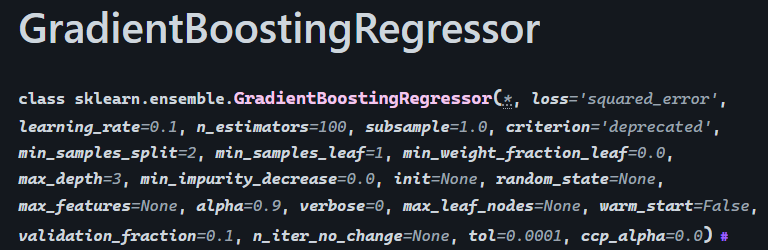

In [10]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in lr:
    for m in max_depth:
        for n in n_estimators:
            gdr = GradientBoostingRegressor(random_state=26,learning_rate=l, n_estimators= n, max_depth= m)
            gdr.fit(X_train, y_train)
            y_pred = gdr.predict(X_test)
            scores.append([l,m,n,r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

,Learning Rate,Max Depth,N,Score
68,0.504444,3.0,100,0.927796
56,0.405556,3.0,100,0.927673
77,0.603333,2.0,100,0.927434
101,0.801111,2.0,100,0.925072
53,0.405556,2.0,100,0.924303
...,...,...,...,...
0,0.010000,NaN,25,0.354160
4,0.010000,2.0,50,0.314529
9,0.010000,4.0,25,0.279623
6,0.010000,3.0,25,0.244498


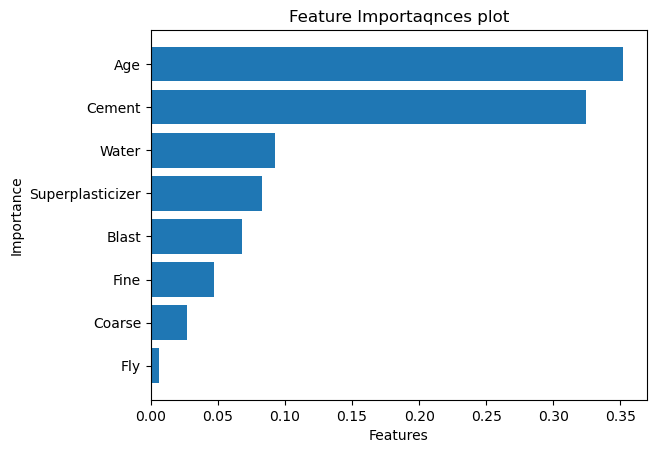

In [13]:
best_model = GradientBoostingRegressor(random_state=26,max_depth=3,
                                  learning_rate=0.504444,n_estimators=100)
best_model.fit(X,y)
df_imp = pd.DataFrame({"features":list(X.columns),
                       "importance": best_tree.feature_importances_})
# plt.figure(figsize=(16,10))
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp["features"],df_imp["importance"])
plt.title("Feature Importaqnces plot")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()